In [1]:
from math import ceil
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
from pyspan.io import pack_trace
from flups.io import load_txt, save_txt
from flups.analysis import despike_median, despike_median_slow, despike_median_p, despike_median_partition
from pyspan.utils import nm2ev, between
from ipywidgets import interact, interactive, fixed, interact_manual, GridspecLayout, AppLayout, Button
import ipywidgets as widgets
from numpy.polynomial import Polynomial
from scipy.interpolate import InterpolatedUnivariateSpline
from scipy.spatial.distance import cdist, correlation
#import colorcet as cc
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter
#import scistyles
from tqdm import tqdm
from scipy.ndimage import spline_filter, gaussian_filter
import scipy.constants as const

In [2]:
def nm2eV(nm):
    return const.h * const.c / (const.e * nm * 1e-9) 

def spectra_view(w, t, dat1, ylim=[-30,40], compare=False, dat2=0, name1='dat1', name2='dat2'):
    'interactive view for clicking though spectra'
    fig, ax = plt.subplots(dpi=80, figsize=(10, 5))
    line_1, = ax.plot(w, dat1[:, 0], color='k', label=name1, linewidth=0.8)
    if compare==True:
        line_2, = ax.plot(w, dat2[:, 0], color='b', label=name2, linewidth=0.8)
    plt.axhline(0, color='k', lw=0.6)
    ax.set_xlim(247, 448)
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_xlabel('wavelength / nm')
    ax.set_ylabel(f"$\Delta OD$/ $10^3$")
    ax.set_title(f'Delay = {t[0]:.1f} ps')
    ax.grid()
    ax.legend()
    plt.tight_layout()

    def update(time_index):
        line_1.set_ydata(dat1[:, time_index])
        if compare==True:
            line_2.set_ydata(dat2[:, time_index])
        ax.set_title(f'delay = {t[time_index]:.2f} ps')
        fig.canvas.draw_idle()

    return interact(update, time_index=(0, len(t) - 1, 1));

In [3]:
%matplotlib widget
#plt.style.use("report-sp")

# Select files


In [48]:
load_path = r'C:\Users\Felix\Desktop\Machines_FLUPS\data\corrections'

#  select files
#nums = 16, 17, 19, 23, 25, 26, 27, 28
nums = 7, 77
#nums = 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28
#nums = range()
fnames = [f"run{i:02d}.dat" for i in nums] # old: [f"240619_run{i:02d}.txt" for i in nums]
# setup an output root file name
out_root = fnames[0][:-6]+f"{nums[0]:02d}{nums[-1]:02d}"
fnames, out_root

(['run07.dat', 'run77.dat'], 'run0777')

In [49]:
# run, tmax, step
# 1, 30, 250
# 2, 6, 100
# 3, 20, 250 
# 4, -"-

In [50]:
#THis is changed from original because there was a bug in original 

import os

dat = {fn: load_txt(os.path.join(load_path, fn)) for fn in fnames}

for fn, (t, wl, s) in dat.items():
    if t[1]<t[0]:
        t = t[::-1]
        s = s[::-1,:]
    s = s.T
    dat[fn] = (t, wl, s)

In [51]:
# Check all times are the same
all_t = np.array([d[0] for d in dat.values()])
assert np.allclose(all_t[0], all_t)
t = all_t[0]
# Check all wavelengths are the same
all_wl = np.array([d[1] for d in dat.values()])
assert np.allclose(all_wl[0], all_wl)
wl = all_wl[0]
pix = np.arange(wl.size)
if np.allclose(wl, np.arange(wl.size)+1): # convert pixels to energy
    wl_u = pix*0.123+248.7656

# Load all the delta A data.
sig = np.array([d[2] for d in dat.values()])
org = sig.copy()
# subtract before time 0
#bksub = dod - np.mean(dod.compress(t<-0.15, axis=2), axis=2)[:,:,np.newaxis]

In [52]:
# The axes of dod are: files, wl, time
sig.shape, (len(fnames), wl.size, t.size)

((2, 1600, 401), (2, 1600, 401))

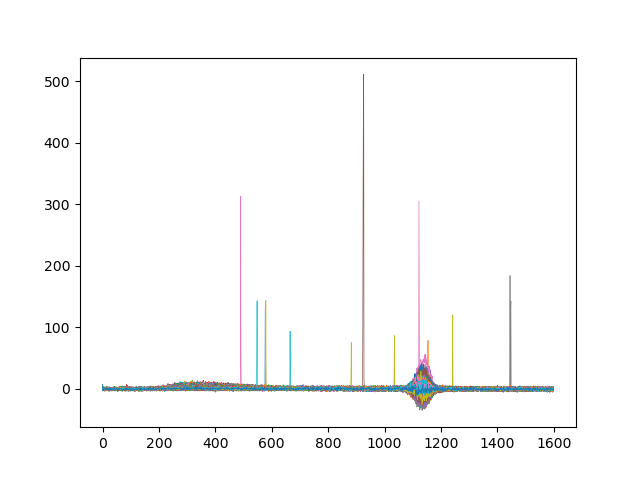

In [53]:
plt.figure()
for i in range(len(t)):
    plt.plot(sig[1,:,i],lw=0.5)
plt.show()

In [54]:
print(sig.shape)

(2, 1600, 401)


# plot the traces

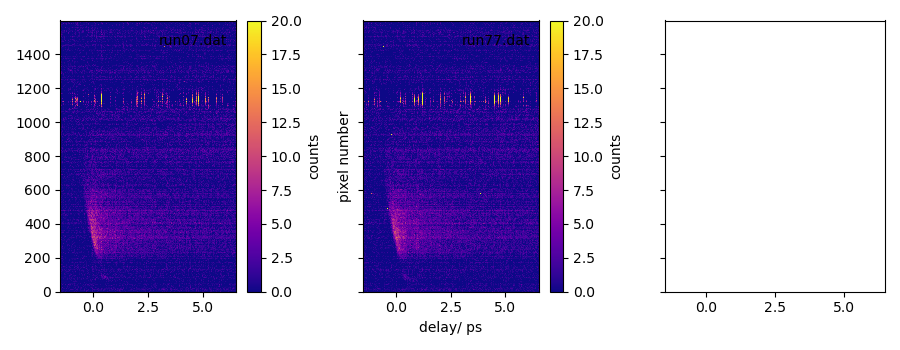

In [55]:
colorscheme = "Blues" # new

vmin, vmax = 0, 20#-50,50 #np.percentile(sig, [10, 99])

nrows = ceil(len(fnames)/2)
fig, axes = plt.subplots(nrows=nrows, ncols=3, sharex=True, sharey=True, figsize=(9,nrows*3.5), dpi=100)
for i, (fn, ax) in enumerate(zip(fnames, axes.flat)):
    plt.sca(ax)
    mesh = plt.pcolormesh(t, pix, sig[i,:,:], cmap="plasma", vmin=vmin, vmax=vmax) # old: cmap="cet_CET_L17"
    plt.colorbar(mesh, ax=ax, label=f"counts") # new
    plt.text(0.95, 0.95, fnames[i], transform=ax.transAxes, va="top", ha="right")
plt.xlabel('delay/ ps')
plt.ylabel('pixel number')
plt.tight_layout()
plt.show()

In [56]:
spectra_view(wl, t, sig[0,:,:], ylim=[-2,8], compare=True, dat2=sig[3, :,:], name1='WT401_first', name2='WT401_last')

IndexError: index 3 is out of bounds for axis 0 with size 2

In [57]:

# save first and last scan only with pixel converted to wavelength

#save_txt("250825_LCH_FLUPS_run01_Only-wl-cali.txt", wl_u, t, sig[0,:,:])
#save_txt("250825_LCH_FLUPS_run02_Only-wl-cali.txt", wl_u, t, sig[0,:,:])
#save_txt("250825_LCH_FLUPS_run03_Only-wl-cali.txt", wl_u, t, sig[0,:,:])
#save_txt("250825_LCH_FLUPS_run09_Only-wl-cali.txt", wl_u, t, sig[-1,:,:])

# spike detection and filtering

2it [00:03,  1.71s/it]


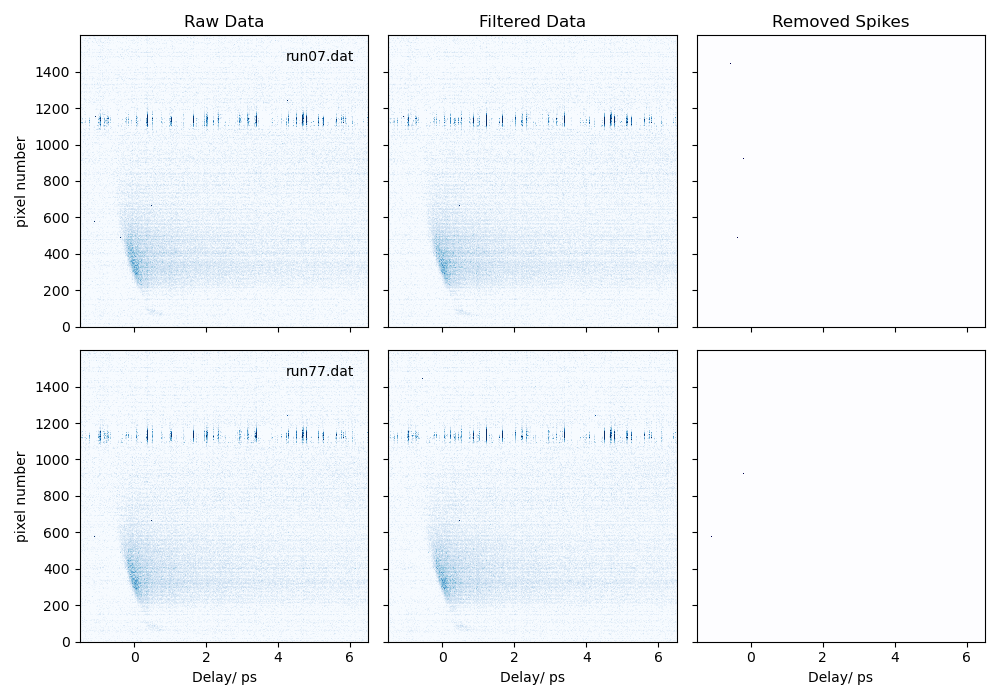

In [58]:
# calculate threshold for spike detection

#lo, hi = np.percentile(
#    sig.compress(t<-1.4, axis=-1).compress(
#        ~between(pix, 614, 680), axis=1), # QUESTION: Why excluding the 614-680 pixel region? Guess pump?
#        [5, 95])
lo, hi = (0,50)
thres = (hi-lo)*2
filter_len = (15,5)

# Filter out spikes and plot results
nrows = len(fnames)
fig, axes = plt.subplots(nrows=nrows, ncols=3, sharex=True, sharey=True, figsize=(10,nrows*3.5))
axes = np.atleast_2d(axes)
filt = []
for i, fn in tqdm(enumerate(fnames)):
    filt.append(despike_median(sig[i,:,:], filter_len, threshold=thres))
    plt.sca(axes[i,0])
    plt.pcolormesh(t, pix, sig[i,:,:], cmap=colorscheme, vmin=vmin, vmax=vmax)
    plt.text(0.95, 0.95, fnames[i], transform=plt.gca().transAxes, va="top", ha="right")
    plt.sca(axes[i,1])
    plt.pcolormesh(t, pix, filt[i], cmap=colorscheme, vmin=vmin, vmax=vmax)
    plt.sca(axes[i,2])
    plt.pcolormesh(t, pix, sig[i,:,:]-filt[i], cmap="seismic_r", vmin=-vmax/100, vmax=vmax/100)
for ax in axes[:,0]:
    ax.set_ylabel(r"pixel number")
for ax in axes[-1,:]:
    ax.set_xlabel(r"Delay/ ps")
axes[0,0].set_title("Raw Data")
axes[0,1].set_title("Filtered Data") 
axes[0,2].set_title("Removed Spikes")
plt.tight_layout()
plt.show()

# NOTE: Deleted the cell that was coming after this one

despike benchmarking

despike_median
  (compare median to absolute threshold). eats the XC, misses many cosmics. threshold 100
  (15,3) 1.21 it/s

despike_median_p
  (compare median to p95-p5): Works well, but horribly slow
  (15,3) 36.52s/it. threshold 2. 
  (15,5) takes 42 s/it, threhsold 2.

From the litterature: compare to sigma of background pixel: use despike_median fast, but for threshold pass std of a valid background section. Threshold ~ 2 * (p95 - p5)

In [59]:
# continue with filtered data and subtract background
sig = np.array(filt)
#sig = sig- sig.compress(t<-1.4, axis=2).mean(axis=2)[:,:,np.newaxis] # Here we have to set a t that we measured, and that contains only BG. otherwise it does not work. generall this ismfor the odd case where there was a cosmic before t0.

# Compute RMDS, reject bad pulses and average

In [60]:
# Close graphs to save memory
plt.close("all")

In [61]:
# this does not seem necessary ever in flups.
# We should perhaps do a "trimmed average" instead. Ie: compute std and median vs repetition, reject above some difference threshold

# If there is too much scatter, we should remove the pump scatter from rmsd calculation
# This is done by setting finite bounds for `pump_lo`, `pump_hi`
pump_lo, pump_hi = 100, 300 # old: 790, 880, oldold: 600, 670
sub_temp = sig.compress(~between(pix, pump_lo, pump_hi) & ~between(pix, -np.infty, 400), axis=1)

# compute median for all files at a given delay and wavelength
# then, compute rmsd. This was done using "euclidean distance" because I was playing around
medn = np.ma.median(sub_temp, axis=0)
rmsd = np.array([
    cdist(sub_temp[:,:,i], [ medn[:,i]], metric="euclidean",)
    for i in range(sig.shape[-1])])
rmsd = rmsd.squeeze().T # 


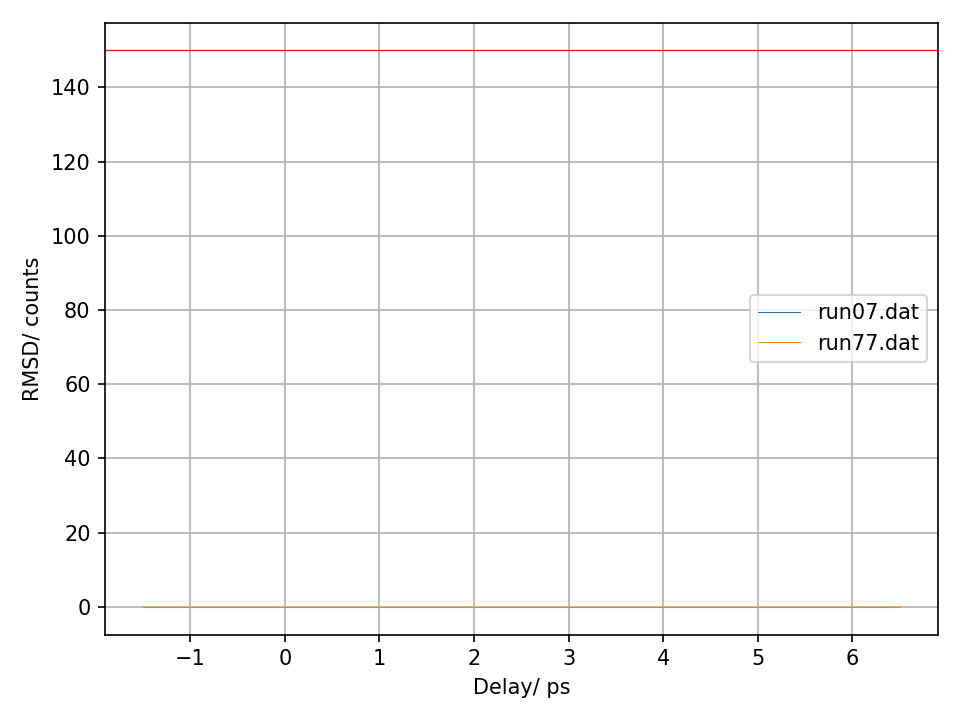

In [62]:
# set the threshol for rejection, and reject these pulses
# This is implemented using a "masked array" (see `numpy.ma`)
threshold = 150#2000

plt.figure(dpi=150)
plt.plot(t, rmsd.T, "-", lw=0.5, label=fnames)
plt.axhline(threshold, color='r', linewidth=0.6) # Daria
plt.xlabel("Delay/ ps")
plt.ylabel("RMSD/ counts")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [63]:
is_bad = rmsd > threshold
sig_masked = np.ma.masked_where(
    np.broadcast_to(np.atleast_2d(is_bad)[:,np.newaxis,:], sig.shape),  # use `is_bad`, but ensure it has the correct shape
    np.ma.getdata(sig)  # get the original data from dod
)

interactive(children=(IntSlider(value=0, description='i', max=1599), IntRangeSlider(value=(0, 1), description=…

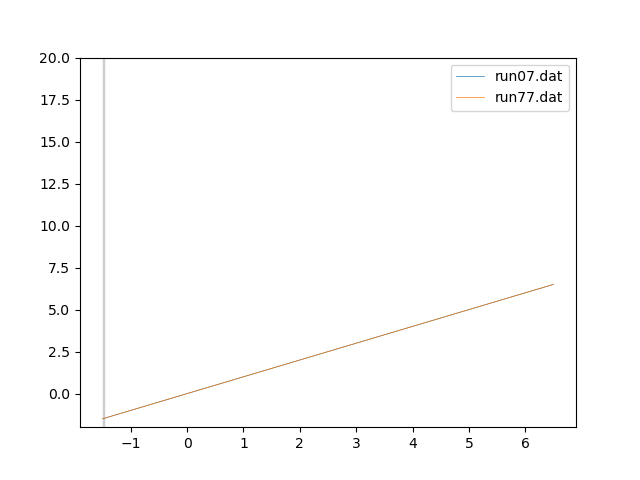

In [64]:
# Plot the kinetic transients at specific wavelength.
# the `wl` cursor controls which wl is displayed.
# The `bnds` cursor are just there to help indentify bounds for manual rejection

fig = plt.figure(dpi=100) #(dpi=150)

i = 0
ymin = -2 #np.min(sig)
ymax = 20 #np.max(sig)
curves = plt.plot(t, sig_masked[:,i,:].T, lw=0.5, label=fnames)
span = plt.axvspan(0, 1, color="0.8")
plt.ylim(ymin, ymax)
plt.legend()

idx = widgets.IntSlider(i, 0, len(pix)-1)
idx.desc_fmt = "pix = {:.02f}"


@interact(i=idx, bnds = widgets.IntRangeSlider(value=[0,1], min=0, max=len(t)-1))
def _update(i, bnds):
    for j, c in enumerate(curves):
        c.set_ydata(sig_masked[j,i,:])
    idx.description = idx.desc_fmt.format(pix[i])
    lo, hi = bnds
    span.xy[[0,1,4],0] = t[lo]
    span.xy[[2,3],0] = t[hi]

In [65]:
# You can reject specific pulses manually like in the lines below.
# We assign the value `np.ma.masked` to slices in dod_masked. This masks the value/
# The slice is as follows: [file_index, all the spectrum, a range indices]
# file_index is the position of the file in `fnames`,
# : means do it for the whole spectrum
# range(a, b) reject indices a to b, excluding the endpoint

#sig_masked[-1,[282,283],:] = np.ma.masked # reject specific rows where background had a cosmic.

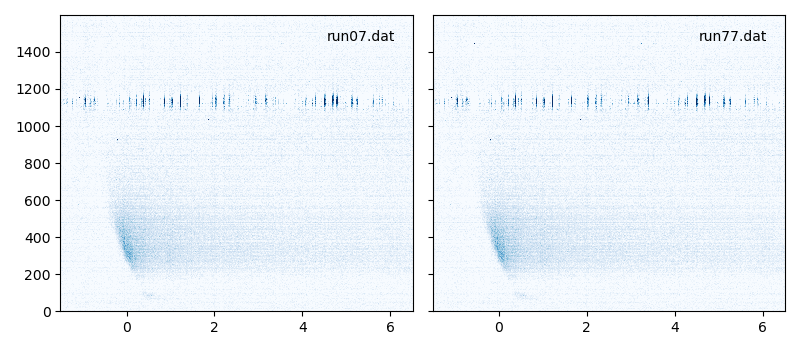

In [66]:
# Inspect the traces after rejection
nrows = ceil(len(fnames)/2)
fig, axes = plt.subplots(nrows=nrows, ncols=2, sharex=True, sharey=True, figsize=(8,nrows*3.5))
for i, (fn, ax) in enumerate(zip(fnames, axes.flat)):
    plt.sca(ax)
    plt.pcolormesh(t, pix, sig_masked[i,:,:], cmap=colorscheme, vmin=vmin, vmax=vmax)
    plt.text(0.95, 0.95, fnames[i], transform=ax.transAxes, va="top", ha="right")
plt.tight_layout()

In [67]:
# Perform the average, rejecting the masked values
avg = np.ma.mean(sig_masked, axis=0)
#avg_early = np.ma.mean(sig_masked.compress(np.arange(sig_masked.shape[0])% 4 < 2, axis=0), axis=0)
#avg_late = np.ma.mean(sig_masked.compress(np.arange(sig_masked.shape[0])% 4 > 2, axis=0), axis=0)

#save_txt("250827_FLUPS_pcf_"+out_root+".txt", t, wl_u, avg.T)
#save_txt(out_root+"_early.txt", t, wl_u, avg_early.T)
#save_txt(out_root+"_late.txt", t, wl_u, avg_late.T)
print(avg.shape)

(1600, 401)


In [68]:
# Perform the average, rejecting the masked values
avg1 = np.ma.mean(sig_masked, axis=0)
avg2=np.ma.mean(avg1, axis=1)
#avg_early = np.ma.mean(sig_masked.compress(np.arange(sig_masked.shape[0])% 4 < 2, axis=0), axis=0)
#avg_late = np.ma.mean(sig_masked.compress(np.arange(sig_masked.shape[0])% 4 > 2, axis=0), axis=0)

#save_txt("250827_FLUPS_pcf_"+out_root+".txt", t, wl_u, avg.T)
#save_txt(out_root+"_early.txt", t, wl_u, avg_early.T)
#save_txt(out_root+"_late.txt", t, wl_u, avg_late.T)

print(avg2.shape)

(1600,)


NameError: name 'wl_u' is not defined

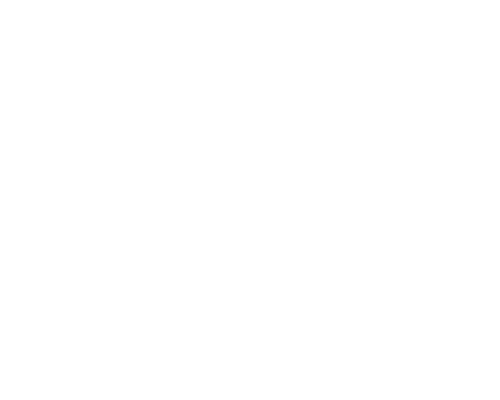

In [69]:
plt.figure(figsize=(5,4))
plt.plot(wl_u, avg2)

print(sig[0,:,:])
print(avg1)

## Plot the average

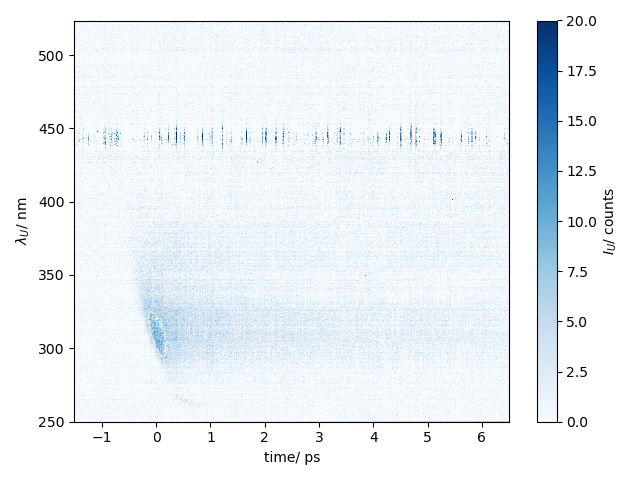

In [70]:
#avg=sig[0,:,:]

#changed wl_u to wl

plt.figure()
plt.pcolormesh(t, wl, avg, cmap=colorscheme, vmin=vmin, vmax=vmax)
cb = plt.colorbar(label=r"$I_U$/ counts")
#lines = plt.contour(t, wl, savgol_filter(avg, 9, 2, axis=0), levels = np.arange(0, np.max(avg), hi/4)[1:], colors="w", linewidths=0.5)
lines = plt.contour(t, wl, gaussian_filter(avg, [3, 1]), levels = np.arange(0, hi*2, hi/8)[1:], colors="w", linewidths=0.5)
plt.xlabel("time/ ps")
plt.ylabel(r"$\lambda_U$/ nm")

plt.tight_layout()
#plt.savefig(out_root+"_avg_magma.png", dpi=300)
plt.show()

In [71]:
#np.savetxt("260526_continuum", pack_trace(t, wl, avg), fmt="%0.6e")

# Do t0 correction

In [72]:
# load t0 curve
t0_params = np.loadtxt("260605_FLUPS_t0_corr.txt").T

# evaluate t0 curve for present wavelength range
t0_eval = np.poly1d(t0_params)(nm2eV(wl))
t0_corr = np.column_stack((wl, t0_eval))

print(t0_params)

[ 0.05701212  0.24674    -1.99836162]


In [73]:
# Perform correction.
# Define a function to do the shift
def shift_kin(t, y, t0):
    return np.interp(t+t0, t, y, left=np.nan, right=np.nan)

# Initialize an empty array 
shifted = np.zeros_like(avg, subok=False)
print(shifted.shape)
# Perform the shift for every wavelength
for i in range(avg.shape[0]):
    shifted[i,:] = shift_kin(t, avg[i,:], t0_corr[i,1])
print(shifted.shape)
# clip the edges which include missing data
has_invalid = ~np.any(np.isnan(shifted), axis=0)
# results is in t_c (clipped time axis) and `shifted`
t_c = t#.compress(has_invalid)
#shifted = shifted.compress(has_invalid, axis=1)
print(shifted.shape)

(1600, 401)
(1600, 401)
(1600, 401)


In [74]:
print(avg.shape[1])

401


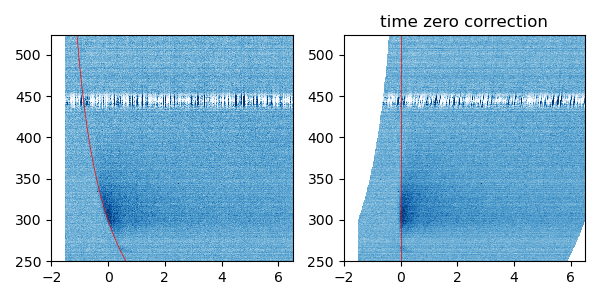

In [75]:
fig, axes = plt.subplots(ncols=2, figsize=(6,3)) #size(8,4)
plt.sca(axes[0])
plt.pcolormesh(t, wl, avg, vmin=-10, vmax=10, cmap="Blues")
_, t0 = t0_corr.T
plt.plot(t0, wl, color="r", lw=0.5)
plt.xlim(-2,6.5)
plt.sca(axes[1])
plt.pcolormesh(t_c, wl, shifted, vmin=-10, vmax=10, cmap="Blues")
plt.axvline(0, color="r", lw=0.5) 
plt.xlim(-2,6.5)
plt.title('time zero correction') 
plt.tight_layout()
plt.show()

In [76]:
#np.savetxt("WT401_no_PCF.dat", pack_trace(t_c, wl, shifted), fmt="%0.6e")

In [77]:
#for saving cropped version

mask = (t_c > -1) & (t_c < 5.5)

t_sel = t_c[mask]
shifted_sel = shifted[:, mask]
'''
np.savetxt(
    "WT402_1112_no_PCF_cropped.dat",
    pack_trace(t_sel, wl, shifted_sel),
    fmt="%0.6e"
)




SyntaxError: incomplete input (4170608123.py, line 7)

NameError: name 't_sel' is not defined

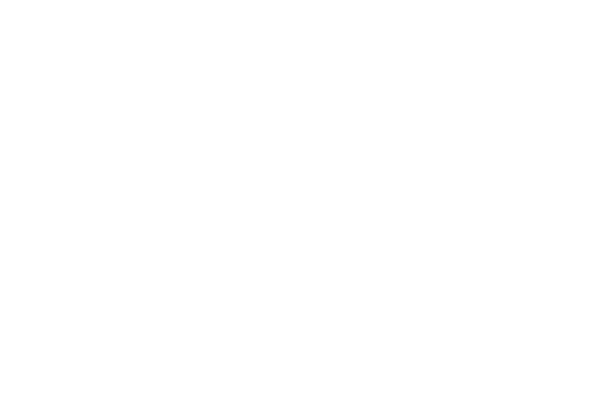

In [78]:
plt.figure(figsize=(6,4))

plt.pcolormesh(
    t_sel,
    wl,
    shifted_sel,
    shading="auto",
    cmap="RdBu_r",
    vmin=-10,
    vmax=10
)

plt.colorbar(label="signal")
plt.xlabel("time / ps")
plt.ylabel("wavelength / nm")
plt.xlim(-0.5, 5.5)
#plt.savefig("WT_401_noPCF", dpi=300)
plt.tight_layout()
plt.show()

interactive(children=(IntSlider(value=200, description='time_index', max=400), Output()), _dom_classes=('widge…

<function __main__.spectra_view.<locals>.update(time_index)>

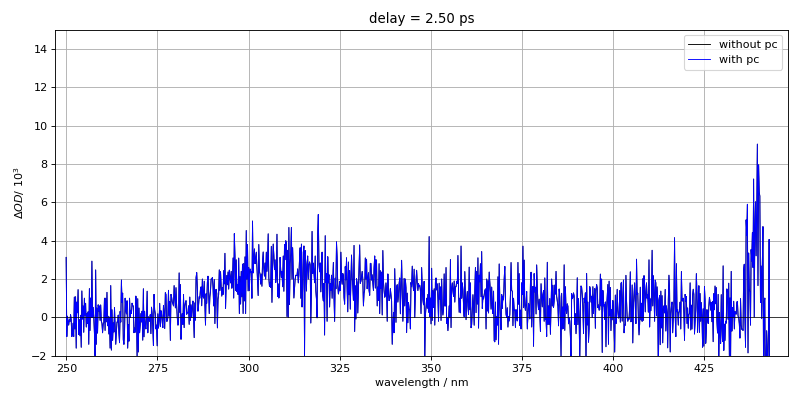

In [79]:
spectra_view(wl, t_c, shifted, ylim=[-2,15], compare=True, dat2=shifted, name1='without pc', name2='with pc')

# Do pc correction

In [80]:
pcf = np.load("260605_pcf.npz")

pcf_interp = np.interp(wl, pcf["wl"], pcf["pcf"])  
shifted_pcf = shifted * pcf_interp[:,np.newaxis]

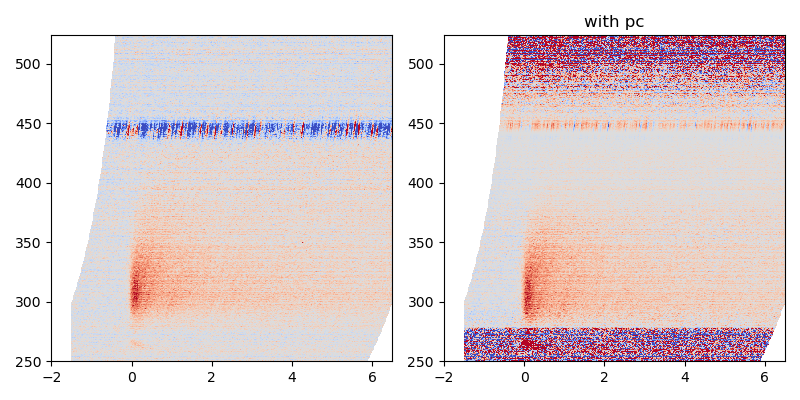

In [81]:
fig, axes = plt.subplots(ncols=2, figsize=(8,4))
plt.sca(axes[0])
plt.pcolormesh(t_c, wl, shifted, vmin=-10, vmax=10, cmap="coolwarm")
plt.xlim(-2,t_c[-1])
plt.sca(axes[1])
plt.pcolormesh(t_c, wl, shifted_pcf, vmin=-10, vmax=10, cmap="coolwarm")
plt.xlim(-2,t_c[-1])
plt.title('with pc') 
plt.tight_layout()
#plt.savefig("Zm_FLUPS_artifact.png", dpi=400)
plt.show()

interactive(children=(IntSlider(value=200, description='time_index', max=400), Output()), _dom_classes=('widge…

<function __main__.spectra_view.<locals>.update(time_index)>

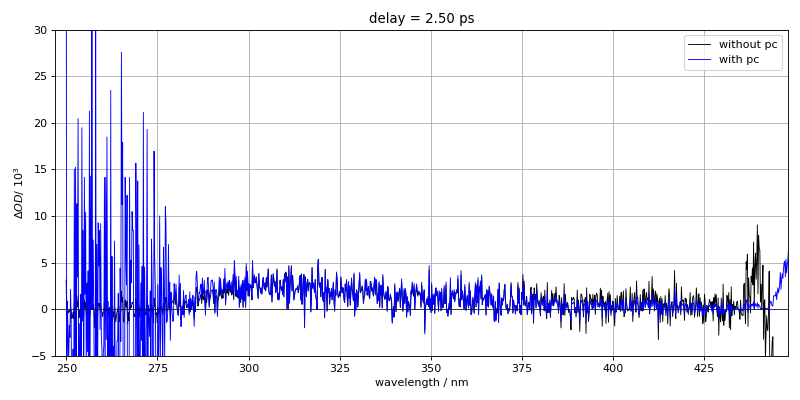

In [82]:
spectra_view(wl, t_c, shifted, ylim=[-5,30], compare=True, dat2=shifted_pcf, name1='without pc', name2='with pc')

# Save processed data ヽ(•‿•)ノ

In [83]:
wl_f = 1/(1/wl - 1/1340) # do downconversion

In [84]:
#this is just to check something
#no downconversion on this one
#wl_f=wl_u

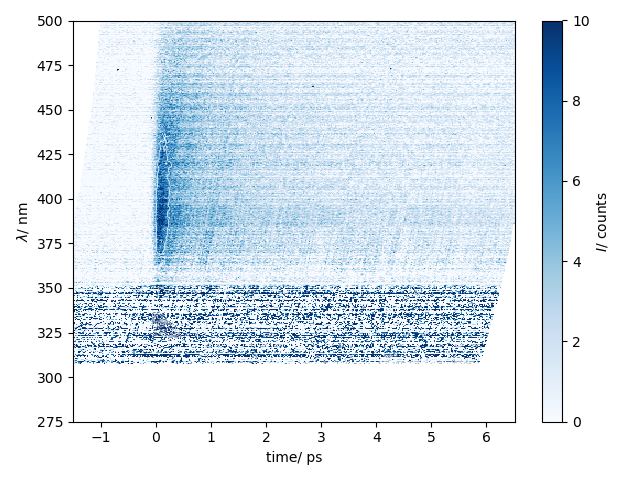

In [85]:
#save_path = r'C:\Users\daria\Dokumente\Physik\AG-Stähler\master thesis\data\LCH motor\FLUPS\250825\fully_corrected_data'

clim=10

plt.figure()
plt.pcolormesh(t_c, wl_f, shifted_pcf, cmap=colorscheme, vmin=0, vmax=clim)
cb = plt.colorbar(label=r"$I$/ counts")
lines = plt.contour(t_c, wl_f, gaussian_filter(shifted_pcf, [3, 1]), levels = np.arange(0, hi*2, hi/8)[1:], colors="w", linewidths=0.5)
plt.ylim(275, 500)
plt.xlabel("time/ ps")
plt.ylabel(r"$\lambda$/ nm")
plt.tight_layout()
#plt.savefig("Zs_FLUPS_no_donwconversion.png", dpi=400)
plt.show()

In [86]:
#np.savetxt("260605_WT401_first", pack_trace(t_c, wl_f, shifted_pcf), fmt="%0.6e")

In [47]:

mask = (t_c > -1) & (t_c < 5.5)

t_sel = t_c[mask]
shifted_sel = shifted_pcf[:, mask]
'''
np.savetxt(
    "260605_WT402_ac_cropped.dat",
    pack_trace(t_sel, wl_f, shifted_sel),
    fmt="%0.6e"
)